In [ ]:
%pip install ydata-profiling

In [ ]:
import pandas as pd
from ydata_profiling import ProfileReport

# Step 1: Load dataset
df = pd.read_csv("AI Job Market & Salary Trends 2025.csv")

# Step 2: Display basic information
print("First 5 rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

# Step 3: Generate Pandas Profiling Report
profile = ProfileReport(
    df,
    title="Exploratory Data Analysis Report",
    explorative=True
)

# Step 4: Save report as HTML
profile.to_file("EDA_Report.html")

print("\nEDA Report generated successfully!")

DATASET LOADED SUCCESSFULLY

First 5 Records:
    job_id              job_title  salary_usd salary_currency  \
0  AI00001  AI Research Scientist       90376             USD   
1  AI00002   AI Software Engineer       61895             USD   
2  AI00003          AI Specialist      152626             USD   
3  AI00004           NLP Engineer       80215             USD   
4  AI00005          AI Consultant       54624             EUR   

  experience_level employment_type company_location company_size  \
0               SE              CT            China            M   
1               EN              CT           Canada            M   
2               MI              FL      Switzerland            L   
3               SE              FL            India            M   
4               EN              PT           France            S   

  employee_residence  remote_ratio  \
0              China            50   
1            Ireland           100   
2        South Korea             0   
3 

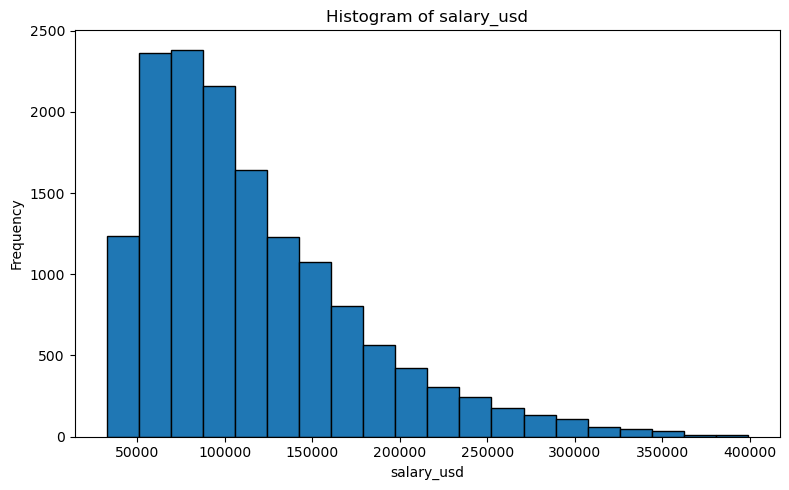

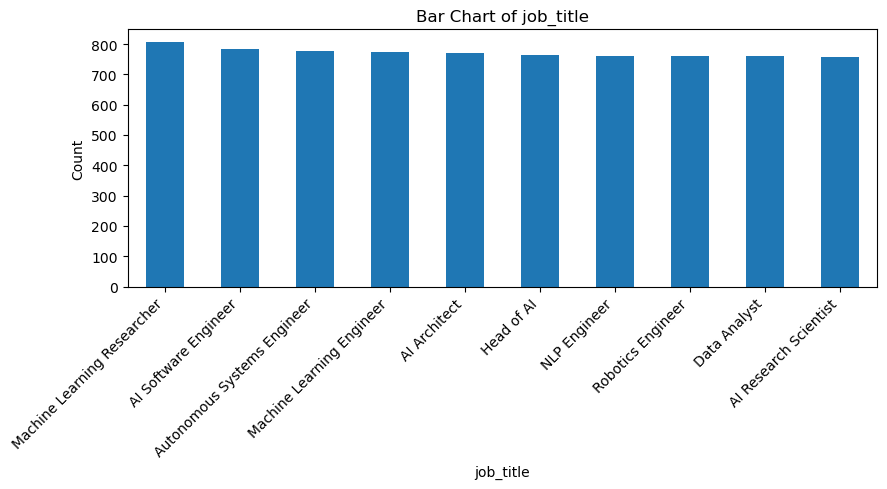

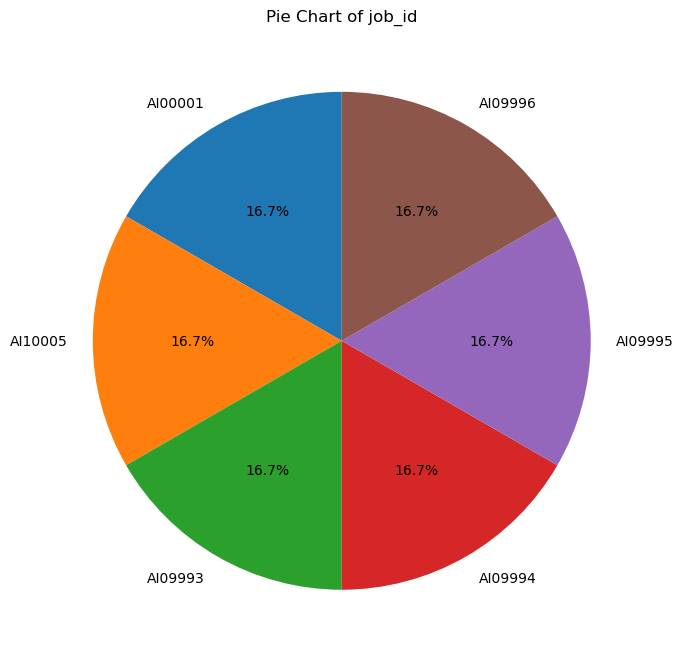

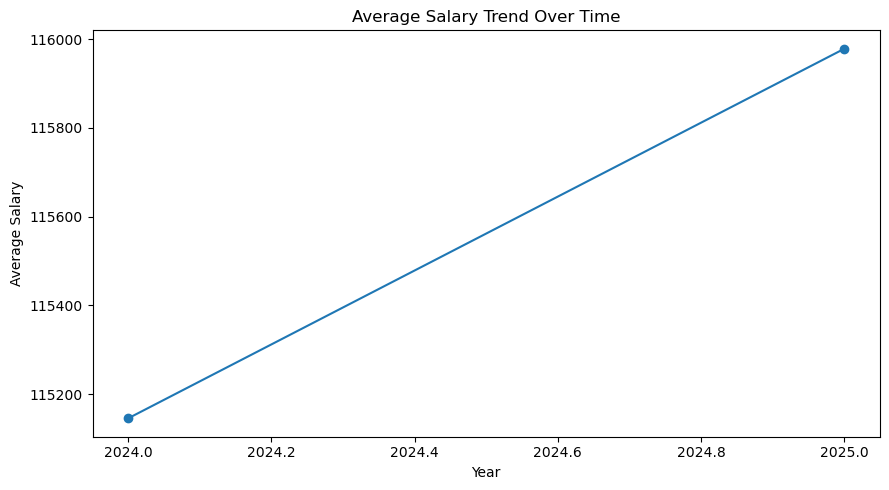

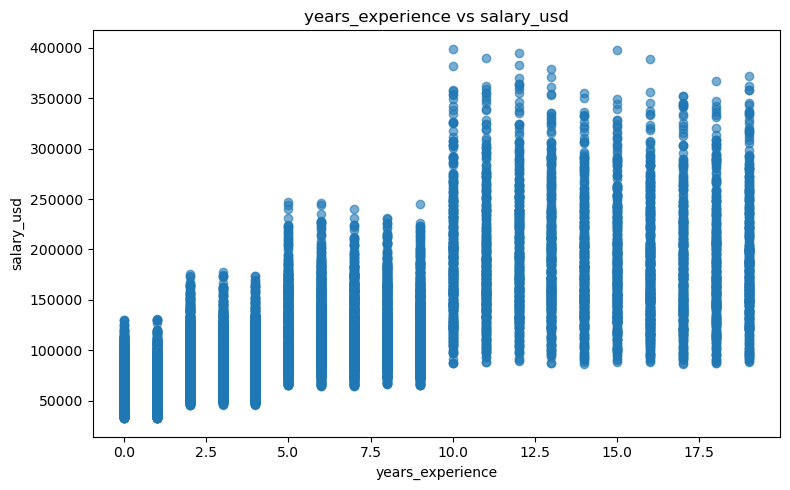


Correlation Matrix:
                        salary_usd  remote_ratio  years_experience  \
salary_usd                1.000000      0.013727          0.737556   
remote_ratio              0.013727      1.000000          0.015321   
years_experience          0.737556      0.015321          1.000000   
job_description_length   -0.009092      0.004475         -0.007526   
benefits_score            0.000985      0.003139         -0.007275   

                        job_description_length  benefits_score  
salary_usd                           -0.009092        0.000985  
remote_ratio                          0.004475        0.003139  
years_experience                     -0.007526       -0.007275  
job_description_length                1.000000        0.006744  
benefits_score                        0.006744        1.000000  


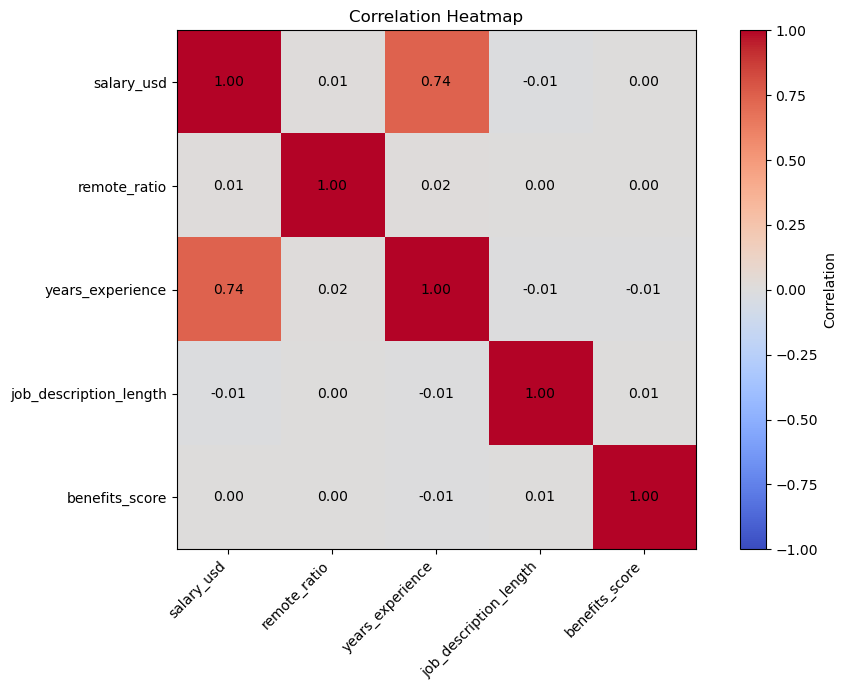

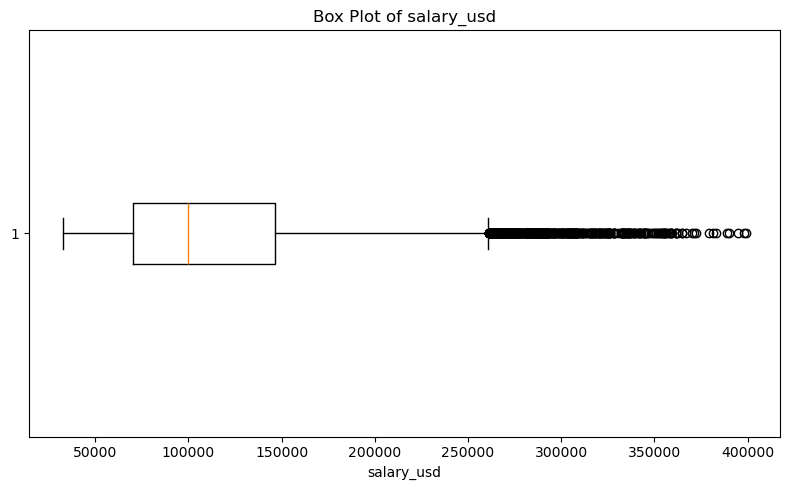


EDA COMPLETED SUCCESSFULLY


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Load Dataset

df = pd.read_csv("AI Job Market & Salary Trends 2025.csv")
df.columns = df.columns.str.strip()

print("DATASET LOADED SUCCESSFULLY")
print("\nFirst 5 Records:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe(include="all"))

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

# 2. Handle Missing Values and Duplicates

numerical_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(include="object").columns.tolist()

for column in numerical_columns:
    if df[column].isnull().sum() > 0:
        df[column] = df[column].fillna(df[column].median())

for column in categorical_columns:
    if df[column].isnull().sum() > 0:
        mode_value = df[column].mode()
        if not mode_value.empty:
            df[column] = df[column].fillna(mode_value[0])

df = df.drop_duplicates()

print("\nDataset Shape After Cleaning:")
print(df.shape)

# 3. Histogram

if numerical_columns:
    column = next(
        (c for c in numerical_columns if "salary" in c.lower()),
        numerical_columns[0]
    )

    plt.figure(figsize=(8, 5))
    plt.hist(df[column].dropna(), bins=20, edgecolor="black")
    plt.title("Histogram of " + column)
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

# 4. Bar Chart

if categorical_columns:
    column = next(
        (c for c in categorical_columns
         if any(word in c.lower() for word in ["job title", "title", "industry"])),
        categorical_columns[0]
    )

    counts = df[column].value_counts().head(10)

    plt.figure(figsize=(9, 5))
    counts.plot(kind="bar")
    plt.title("Bar Chart of " + column)
    plt.xlabel(column)
    plt.ylabel("Count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

# 5. Pie Chart

if categorical_columns:
    column = next(
        (c for c in categorical_columns
         if any(word in c.lower() for word in ["experience level", "employment type", "remote"])),
        categorical_columns[0]
    )

    counts = df[column].value_counts().head(6)

    plt.figure(figsize=(7, 7))
    plt.pie(
        counts,
        labels=counts.index.astype(str),
        autopct="%1.1f%%",
        startangle=90
    )
    plt.title("Pie Chart of " + column)
    plt.tight_layout()
    plt.show()

# 6. Line Chart

date_column = next(
    (c for c in df.columns if "date" in c.lower()),
    None
)

salary_column = next(
    (c for c in numerical_columns if "salary" in c.lower()),
    None
)

if date_column and salary_column:
    df[date_column] = pd.to_datetime(df[date_column], errors="coerce")

    yearly_salary = df.dropna(subset=[date_column]).groupby(
        df.loc[df[date_column].notna(), date_column].dt.year
    )[salary_column].mean()

    if not yearly_salary.empty:
        plt.figure(figsize=(9, 5))
        yearly_salary.plot(kind="line", marker="o")
        plt.title("Average Salary Trend Over Time")
        plt.xlabel("Year")
        plt.ylabel("Average Salary")
        plt.tight_layout()
        plt.show()
    else:
        print("\nNo valid dates available for the line chart.")

elif salary_column:
    salary_trend = df[salary_column].dropna().head(100)

    plt.figure(figsize=(9, 5))
    plt.plot(range(1, len(salary_trend) + 1), salary_trend, marker="o")
    plt.title("Salary Trend Across First 100 Records")
    plt.xlabel("Record Number")
    plt.ylabel("Salary")
    plt.tight_layout()
    plt.show()
else:
    print("\nNo numerical salary column found for the line chart.")

# 7. Scatter Plot

if len(numerical_columns) >= 2:
    x_column = next(
        (c for c in numerical_columns
         if "experience" in c.lower() or "year" in c.lower()),
        numerical_columns[0]
    )

    y_column = salary_column if salary_column and salary_column != x_column else next(
        c for c in numerical_columns if c != x_column
    )

    plt.figure(figsize=(8, 5))
    plt.scatter(df[x_column], df[y_column], alpha=0.6)
    plt.title(x_column + " vs " + y_column)
    plt.xlabel(x_column)
    plt.ylabel(y_column)
    plt.tight_layout()
    plt.show()
else:
    print("\nAt least two numerical columns are required for the scatter plot.")

# 8. Correlation Heatmap

if len(numerical_columns) >= 2:
    correlation = df[numerical_columns].corr()

    print("\nCorrelation Matrix:")
    print(correlation)

    plt.figure(figsize=(10, 7))
    plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
    plt.colorbar(label="Correlation")

    plt.xticks(
        range(len(correlation.columns)),
        correlation.columns,
        rotation=45,
        ha="right"
    )

    plt.yticks(
        range(len(correlation.columns)),
        correlation.columns
    )

    for i in range(len(correlation.columns)):
        for j in range(len(correlation.columns)):
            value = correlation.iloc[i, j]
            if pd.notna(value):
                plt.text(j, i, f"{value:.2f}", ha="center", va="center")

    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()
else:
    print("\nAt least two numerical columns are required for the heatmap.")

# 9. Box Plot

if numerical_columns:
    column = salary_column if salary_column else numerical_columns[0]

    plt.figure(figsize=(8, 5))
    plt.boxplot(df[column].dropna(), vert=False)
    plt.title("Box Plot of " + column)
    plt.xlabel(column)
    plt.tight_layout()
    plt.show()

print("\nEDA COMPLETED SUCCESSFULLY")